# Análise Python — Sistema Financeiro Brasileiro (IF.data, junho/2026)

IF.data — Banco Central do Brasil

**Base de dados:** IF.data — Junho/2026 — Valores em R$ mil  
**Fonte:** https://www3.bcb.gov.br/ifdata
---

Imports e Configuração

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings

# Configurações globais
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.family'] = 'DejaVu Sans'
pd.set_option('display.float_format', '{:,.0f}'.format)
pd.set_option('display.max_columns', 20)

# Constantes
ARQUIVO_DADOS = 'dados/ifdata_junho_2026.csv'
PASTA_SAIDAS = 'saidas'  # gráficos extras, planilhas e base limpa
os.makedirs(PASTA_SAIDAS, exist_ok=True)
COR_PRINCIPAL = '#1B3F7A'
COR_DESTAQUE  = '#C0395A'

# Cortes do ROE do semestre: referência anual (15% e 8%) dividida por dois
ROE_EXCELENTE = 0.075
ROE_BOM = 0.04


def formatar_numero(valor, _=None):
    """Formata um número no padrão brasileiro (ex.: 2.461 ou 12,5)."""
    if abs(valor) >= 100:
        texto = f'{valor:,.0f}'
    else:
        texto = f'{valor:,.2f}'.rstrip('0').rstrip('.')  # 12.50 -> 12.5 / 10.00 -> 10
    # Trocar separadores: 1,234.5 -> 1.234,5
    return texto.replace(',', 'X').replace('.', ',').replace('X', '.')


def formatar_bi(valor, _=None):
    """Formata um valor em R$ bilhões (ex.: R$ 2.461 bi)."""
    return f'R$ {formatar_numero(valor)} bi'


print('✓ Ambiente configurado com sucesso!')
print(f'  Pandas:     {pd.__version__}')
print(f'  NumPy:      {np.__version__}')
print(f'  Matplotlib: {plt.matplotlib.__version__}')

✓ Ambiente configurado com sucesso!
  Pandas:     2.3.3
  NumPy:      2.5.4
  Matplotlib: 3.11.2


Carregamento dos Dados

In [2]:
# Ler o CSV do IF.data
df_raw = pd.read_csv(ARQUIVO_DADOS, sep=';', encoding='utf-8-sig')

print(f'Linhas: {df_raw.shape[0]:,}')
print(f'Colunas: {df_raw.shape[1]}')
print()
print('Colunas disponíveis:')
for col in df_raw.columns:
    print(f'  - {col}')

Linhas: 1,699
Colunas: 21

Colunas disponíveis:
  - Instituição
  - Código
  - Conglomerado Prudencial
  - Conglomerado Financeiro
  - Conglomerado Prudencial.1
  - TCB
  - TC
  - TI
  - Cidade
  - UF
  - Data
  - Ativo Total
  - Carteira de Crédito
  - Títulos e Valores Mobiliários
  - Passivo Exigível
  - Captações
  - Patrimônio Líquido
  - Lucro Líquido
  - Número de Agências
  - Número de Postos de Atendimento
  - Unnamed: 20


In [3]:
# Visualizar as primeiras linhas
df_raw.head(10)

,Instituição,Código,Conglomerado Prudencial,Conglomerado Financeiro,Conglomerado Prudencial.1,TCB,TC,TI,Cidade,UF,...,Ativo Total,Carteira de Crédito,Títulos e Valores Mobiliários,Passivo Exigível,Captações,Patrimônio Líquido,Lucro Líquido,Número de Agências,Número de Postos de Atendimento,Unnamed: 20
0,BANCO DO BRASIL S.A.,0,BB - PRUDENCIAL,C0049906,C0080329,b1,1,1,BRASILIA,DF,...,2.461.086.914,1.065.710.905,714.731.784,2.279.753.810,1.974.660.924,181.333.105,6.216.056,3.932,309,NaN
1,CAIXA ECONOMICA FEDERAL,"360,305",CAIXA ECONÔMICA FEDERAL - PRUDENCIAL,C0051626,C0080738,b1,1,6,BRASILIA,DF,...,2.368.147.225,1.362.330.927,452.416.774,2.249.779.433,2.063.880.327,118.367.792,6.585.794,3.000,868,NaN
2,ITAÚ UNIBANCO S.A.,"60,701,190",ITAU - PRUDENCIAL,C0010069,C0080099,b1,2,8,SAO PAULO,SP,...,2.169.409.565,700.105.223,559.549.223,2.006.548.179,1.842.394.345,162.861.385,19.759.837,1.345,1.403,NaN
3,BANCO BRADESCO S.A.,"60,746,948",BRADESCO - PRUDENCIAL,C0010045,C0080075,b1,2,8,OSASCO,SP,...,1.952.464.273,756.014.814,322.119.751,1.777.233.946,1.545.720.299,175.230.327,12.080.064,2.026,762,NaN
4,BANCO SANTANDER (BRASIL) S.A.,"90,400,888",SANTANDER - PRUDENCIAL,C0030379,C0080185,b1,3,8,SAO PAULO,SP,...,1.209.443.083,365.285.710,260.716.671,1.110.706.856,953.249.578,98.736.227,7.382.760,1.196,2.516,NaN
5,BANCO NACIONAL DE DESENVOLVIMENTO ECONOMICO E ...,"33,657,248",BNDES - PRUDENCIAL,NaN,C0081847,b4,1,4,RIO DE JANEIRO,RJ,...,1.073.403.746,375.703.869,209.161.034,892.700.475,661.452.493,180.703.272,11.153.448,5,0,NaN
6,BANCO BTG PACTUAL S.A.,"30,306,294",BTG PACTUAL - PRUDENCIAL,C0049944,C0080336,b1,2,8,RIO DE JANEIRO,RJ,...,743.258.957,81.617.597,228.588.076,663.705.470,548.000.573,79.553.487,9.471.540,28,0,NaN
7,ITAÚ UNIBANCO HOLDING S.A.,"60,872,504",ITAU - PRUDENCIAL,C0010069,C0080099,b2,2,8,SAO PAULO,SP,...,493.183.395,172.877.389,41.855.441,285.535.078,107.861.159,207.648.317,23.205.024,2,7,NaN
8,"NU FINANCEIRA S.A. - SOCIEDADE DE CRÉDITO, FIN...","30,680,829",NU PAGAMENTOS - PRUDENCIAL,C0052058,C0084693,n1,3,14,SAO PAULO,SP,...,267.624.695,76.080.601,80.369.899,252.606.112,225.759.535,15.018.583,4.194.823,2,0,NaN
9,BANCO SAFRA S.A.,"58,160,789",SAFRA - PRUDENCIAL,C0010083,C0080109,b1,2,8,SAO PAULO,SP,...,256.683.465,93.167.603,46.773.165,238.676.254,204.635.211,18.007.212,1.885.083,133,3,NaN


In [4]:
# Informações sobre tipos e nulos
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1699 entries, 0 to 1698
Data columns (total 21 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Instituição                      1699 non-null   object 
 1   Código                           1622 non-null   float64
 2   Conglomerado Prudencial          866 non-null    object 
 3   Conglomerado Financeiro          244 non-null    object 
 4   Conglomerado Prudencial.1        866 non-null    object 
 5   TCB                              1622 non-null   object 
 6   TC                               1622 non-null   float64
 7   TI                               1622 non-null   float64
 8   Cidade                           1622 non-null   object 
 9   UF                               1622 non-null   object 
 10  Data                             1622 non-null   object 
 11  Ativo Total                      1696 non-null   object 
 12  Carteira de Crédito 

Limpeza e Preparação dos Dados

A base IF.data tem algumas particularidades:
- Valores `NI` = Não Informado (precisam ser removidos ou tratados)
- Linhas totalizadoras ao final (tipos TCB, TC e TI)
- Valores monetários como texto (precisam ser convertidos para número)

In [5]:
# Trabalhar em uma cópia
df = df_raw.copy()

# Remover linhas sem TCB (totalizadoras no final do arquivo)
df = df[df['TCB'].notna() & (df['TCB'] != '')]

# Remover a coluna vazia criada pelo ';' no fim de cada linha do CSV
df = df.drop(columns=['Unnamed: 20'])

# Dar nomes claros às colunas de conglomerado (o CSV repete 'Conglomerado Prudencial')
df = df.rename(columns={
    'Conglomerado Prudencial': 'Conglomerado Prudencial (Nome)',
    'Conglomerado Financeiro': 'Conglomerado Financeiro (Cód.)',
    'Conglomerado Prudencial.1': 'Conglomerado Prudencial (Cód.)'
})

# Códigos são números inteiros (sem as linhas de totais, não há mais vazios)
for col in ['Código', 'TC', 'TI']:
    df[col] = df[col].astype(int)

print(f'Instituições na base: {len(df):,}')

# Remover linhas com Ativo Total = NI ou vazio
df = df[~df['Ativo Total'].isin(['NI', '', None])]
df = df[df['Ativo Total'].notna()]

print(f'Após filtros: {len(df):,} registros')

Instituições na base: 1,622
Após filtros: 1,571 registros


In [6]:
# Converter colunas financeiras para número
colunas_financeiras = [
    'Ativo Total', 'Carteira de Crédito', 'Títulos e Valores Mobiliários',
    'Passivo Exigível', 'Captações', 'Patrimônio Líquido', 'Lucro Líquido'
]

for col in colunas_financeiras:
    if col in df.columns:
        df[col] = (
            df[col]
            .astype(str)
            .str.replace('.', '', regex=False)
            .str.replace(',', '.', regex=False)
        )
        df[col] = pd.to_numeric(df[col], errors='coerce')

# Converter agências e postos
for col in ['Número de Agências', 'Número de Postos de Atendimento']:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col].astype(str).str.replace('.', '', regex=False), errors='coerce').fillna(0).astype(int)

# Remover duplicatas
df = df.drop_duplicates()
df = df.reset_index(drop=True)

print(f'Base limpa: {len(df):,} registros')
print(f'Colunas numéricas OK: {df[colunas_financeiras].dtypes.tolist()}')

Base limpa: 1,571 registros
Colunas numéricas OK: [dtype('int64'), dtype('int64'), dtype('int64'), dtype('int64'), dtype('int64'), dtype('int64'), dtype('int64')]


In [7]:
# Criar colunas calculadas
# ROE do semestre: o lucro da base é o acumulado de jan–jun/2026, então o ROE não é anualizado.
# Como no Excel, o ROE fica vazio quando o Patrimônio Líquido é zero ou negativo.
df['ROE'] = df['Lucro Líquido'] / df['Patrimônio Líquido'].where(df['Patrimônio Líquido'] > 0)
df['Indice_Credito_Ativo'] = df['Carteira de Crédito'] / df['Ativo Total'].replace(0, np.nan)

# Zero agências aparece nas cooperativas, que registram zero agências na fonte.
# Por isso a coluna indica só a presença de agência física, não se a instituição é digital.
df['Agencia_Fisica'] = (df['Número de Agências'] == 0).map({True: 'Sem agência', False: 'Com agência'})

# Decodificar tipo de controle
tc_map = {1: 'Público', 2: 'Privado Nacional', 3: 'Privado Estrangeiro'}
df['Tipo_Controle'] = df['TC'].map(tc_map)


# Classificar o ROE com os cortes semestrais
def classificar_roe(roe):
    """Classifica o ROE do semestre (número decimal, ex.: 0.12 = 12%)."""
    if pd.isna(roe): return 'Sem dado'
    if roe > ROE_EXCELENTE: return 'Excelente'
    if roe > ROE_BOM: return 'Bom'
    if roe > 0: return 'Fraco'
    return 'Prejuízo'


df['Classe_ROE'] = df['ROE'].apply(classificar_roe)

# Nome curto para os gráficos (alguns nomes passam de 100 caracteres).
# Guarda o começo e o fim do nome: nas cooperativas, o que diferencia uma da outra fica no fim.
df['Nome_Curto'] = df['Instituição'].apply(lambda nome: nome if len(nome) <= 45 else nome[:22] + '...' + nome[-20:])

# Se dois nomes curtos ficarem iguais, acrescentar o código (o gráfico juntaria as barras)
repetidos = df['Nome_Curto'].duplicated(keep=False)
df.loc[repetidos, 'Nome_Curto'] = df.loc[repetidos, 'Nome_Curto'] + ' (' + df.loc[repetidos, 'Código'].astype(str) + ')'
assert df['Nome_Curto'].is_unique

print('Colunas calculadas criadas:')
print('  - ROE (Retorno sobre Patrimônio no semestre)')
print('  - Indice_Credito_Ativo')
print('  - Agencia_Fisica (Com agência/Sem agência)')
print('  - Tipo_Controle (legível)')
print('  - Classe_ROE (Excelente/Bom/Fraco/Prejuízo/Sem dado)')
print('  - Nome_Curto (para os gráficos)')

Colunas calculadas criadas:
  - ROE (Retorno sobre Patrimônio no semestre)
  - Indice_Credito_Ativo
  - Agencia_Fisica (Com agência/Sem agência)
  - Tipo_Controle (legível)
  - Classe_ROE (Excelente/Bom/Fraco/Prejuízo/Sem dado)
  - Nome_Curto (para os gráficos)


Verificação da qualidade

1. Quantos registros têm ROE nulo?
2. Qual a porcentagem de registros nulos em `Lucro Líquido`?
3. Quais são os valores únicos de `TCB` (segmento) na base limpa?

In [8]:
# 1. ROE nulos
roe_nulos = df['ROE'].isna().sum()
print(f'Registros com ROE nulo: {roe_nulos} (Patrimônio Líquido zero ou negativo)')

# 2. % de nulos em Lucro Líquido
pct_nulos_lucro = df['Lucro Líquido'].isna().sum() / len(df) * 100
print(f'% de nulos em Lucro Líquido: {pct_nulos_lucro:.1f}%')

# 3. Valores únicos de TCB
print('Valores únicos de TCB:', sorted(df['TCB'].unique()))
print(f'Quantidade de valores: {df["TCB"].nunique()}')

Registros com ROE nulo: 6 (Patrimônio Líquido zero ou negativo)
% de nulos em Lucro Líquido: 0.0%
Valores únicos de TCB: ['b1', 'b2', 'b3C', 'b3S', 'b4', 'n1', 'n2', 'n4']
Quantidade de valores: 8


Análise Exploratória de Dados (EDA)

O que esses dados mostram antes de eu fazer qualquer análise específica?

In [9]:
# Estatísticas descritivas das variáveis numéricas principais
cols_analise = ['Ativo Total', 'Carteira de Crédito', 'Patrimônio Líquido', 'Lucro Líquido', 'ROE']
df[cols_analise].describe().round(2)

,Ativo Total,Carteira de Crédito,Patrimônio Líquido,Lucro Líquido,ROE
count,"1,571","1,571","1,571","1,571","1,565"
mean,"12,411,045","4,701,571","1,298,954","97,688",0
std,"123,590,535","52,984,186","11,282,647","968,930",1
min,365,"-11,013","-21,385","-581,406",-14
25%,"23,210",0,"11,102",18,0
50%,"293,113","32,400","60,296","1,821",0
75%,"1,799,632","537,952","268,035","14,886",0
max,"2,461,086,914","1,362,330,927","207,648,317","23,205,024",2


In [10]:
# Distribuição por tipo de controle
print('=== Distribuição por Tipo de Controle ===')
print(df['Tipo_Controle'].value_counts())
print()

# Distribuição por segmento
print('=== Distribuição por Segmento (TCB) ===')
print(df['TCB'].value_counts().sort_index())
print()

# Com e sem agência física
print('=== Com e Sem Agência Física ===')
print(df['Agencia_Fisica'].value_counts())
print()
print('Sem agência, por segmento:')
print(df[df['Agencia_Fisica'] == 'Sem agência']['TCB'].value_counts())

=== Distribuição por Tipo de Controle ===
Tipo_Controle
Privado Nacional       1311
Privado Estrangeiro     224
Público                  36
Name: count, dtype: int64

=== Distribuição por Segmento (TCB) ===
TCB
b1     114
b2      50
b3C     27
b3S    710
b4       4
n1     278
n2     205
n4     183
Name: count, dtype: int64

=== Com e Sem Agência Física ===
Agencia_Fisica
Com agência    834
Sem agência    737
Name: count, dtype: int64

Sem agência, por segmento:
TCB
b3S    710
b3C     27
Name: count, dtype: int64


In [11]:
# Resumo por segmento
resumo_segmento = df.groupby('TCB').agg(
    qtd=('Instituição', 'count'),
    ativo_soma=('Ativo Total', 'sum'),
    ativo_medio=('Ativo Total', 'mean'),
    credito_soma=('Carteira de Crédito', 'sum'),
    roe_medio=('ROE', 'mean'),
    lucro_soma=('Lucro Líquido', 'sum'),
    pl_soma=('Patrimônio Líquido', 'sum')
)

# ROE agregado: lucro total ÷ PL total (cada instituição pesa pelo seu tamanho)
resumo_segmento['roe_agregado'] = resumo_segmento['lucro_soma'] / resumo_segmento['pl_soma']
resumo_segmento['pct_ativo'] = (resumo_segmento['ativo_soma'] / resumo_segmento['ativo_soma'].sum() * 100).round(1)
resumo_segmento = resumo_segmento.round(4)

# Mostrar os ROEs em %
print(resumo_segmento.to_string(formatters={
    'roe_medio': '{:.1%}'.format,
    'roe_agregado': '{:.1%}'.format,
    'pct_ativo': '{:.1f}%'.format
}))

     qtd   ativo_soma  ativo_medio  credito_soma roe_medio  lucro_soma     pl_soma roe_agregado pct_ativo
TCB                                                                                                      
b1   114  14285826206  125,314,265    5511754813      2.0%    80608476  1128319398         7.1%     73.3%
b2    50    931799119   18,635,982     430091465     -4.7%    27442031   281796376         9.7%      4.8%
b3C   27    254740242    9,434,824       2759785      4.0%      677773    19556963         3.5%      1.3%
b3S  710    992158870    1,397,407     534336224      3.6%     8584469   139996985         6.1%      5.1%
b4     4   1121980384  280,495,096     410286392      4.0%    11549205   189571979         6.1%      5.8%
n1   278    734344384    2,641,527     384887708     -0.2%     9405388   109344659         8.6%      3.8%
n2   205    261394666    1,275,096        176917     -3.2%     4805470    48811403         9.8%      1.3%
n4   183    915508281    5,002,777     1118751

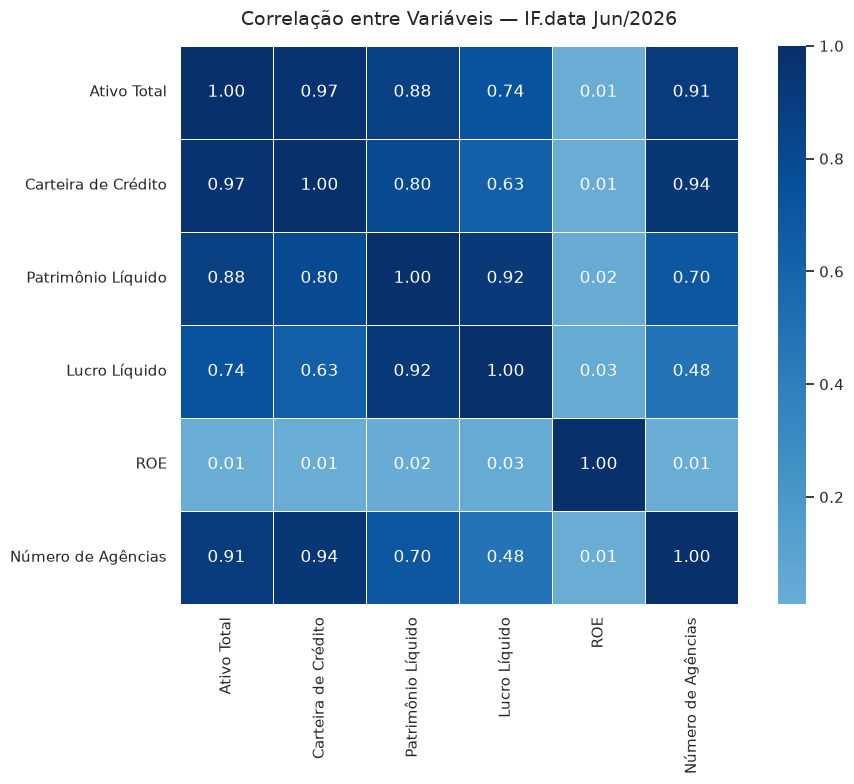

✓ Gráfico salvo: correlacao_ifdata.png


In [12]:
# Matriz de correlação
corr_cols = ['Ativo Total', 'Carteira de Crédito', 'Patrimônio Líquido',
             'Lucro Líquido', 'ROE', 'Número de Agências']
corr = df[corr_cols].corr().round(2)

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='Blues',
            center=0, ax=ax, square=True, linewidths=0.5)
ax.set_title('Correlação entre Variáveis — IF.data Jun/2026', fontsize=14, pad=15)
plt.tight_layout()
plt.savefig('correlacao_ifdata.png', dpi=150, bbox_inches='tight')
plt.show()
print('✓ Gráfico salvo: correlacao_ifdata.png')

Análise exploratória

1. Qual é a mediana do `Ativo Total`? Compare com a média. O que a diferença indica?
2. Quantas instituições têm ROE do semestre acima de 7,5% (Excelente)?
3. Qual a correlação entre `Número de Agências` e `Ativo Total`? O que isso significa?
4. Resumo por `Tipo_Controle` com soma de ativo e ROE médio.

In [13]:
# 1. Mediana vs média do Ativo Total
media_ativo = df['Ativo Total'].mean()
mediana_ativo = df['Ativo Total'].median()
print(f'Média do Ativo Total:   R$ {media_ativo:,.0f} mil')
print(f'Mediana do Ativo Total: R$ {mediana_ativo:,.0f} mil')
print(f'A média é {media_ativo / mediana_ativo:.1f} vezes a mediana')
print()

# 2. Instituições com ROE do semestre acima de 7,5% (Excelente)
roe_excelente = (df['Classe_ROE'] == 'Excelente').sum()
print(f'Instituições com ROE do semestre acima de {ROE_EXCELENTE:.1%} (Excelente): {roe_excelente}')
print()

# 3. Correlação agências x ativo
correlacao = df['Número de Agências'].corr(df['Ativo Total'])
print(f'Correlação entre Número de Agências e Ativo Total: {correlacao:.2f}')
print()

# 4. Resumo por Tipo_Controle
resumo_controle = df.groupby('Tipo_Controle').agg(
    qtd=('Instituição', 'count'),
    ativo_soma=('Ativo Total', 'sum'),
    roe_medio=('ROE', 'mean')
)

print('=== Resumo por Tipo de Controle ===')
for controle, linha in resumo_controle.iterrows():
    print(f'{controle}: {linha["qtd"]:.0f} instituições | '
          f'ativo R$ {linha["ativo_soma"]:,.0f} mil | ROE médio {linha["roe_medio"]:.1%}')

Média do Ativo Total:   R$ 12,411,045 mil
Mediana do Ativo Total: R$ 293,113 mil
A média é 42.3 vezes a mediana

Instituições com ROE do semestre acima de 7.5% (Excelente): 458

Correlação entre Número de Agências e Ativo Total: 0.91

=== Resumo por Tipo de Controle ===
Privado Estrangeiro: 224 instituições | ativo R$ 3,344,608,873 mil | ROE médio -3.4%
Privado Nacional: 1311 instituições | ativo R$ 9,761,967,942 mil | ROE médio 1.4%
Público: 36 instituições | ativo R$ 6,391,175,337 mil | ROE médio 8.0%


Visualização com Matplotlib e Seaborn

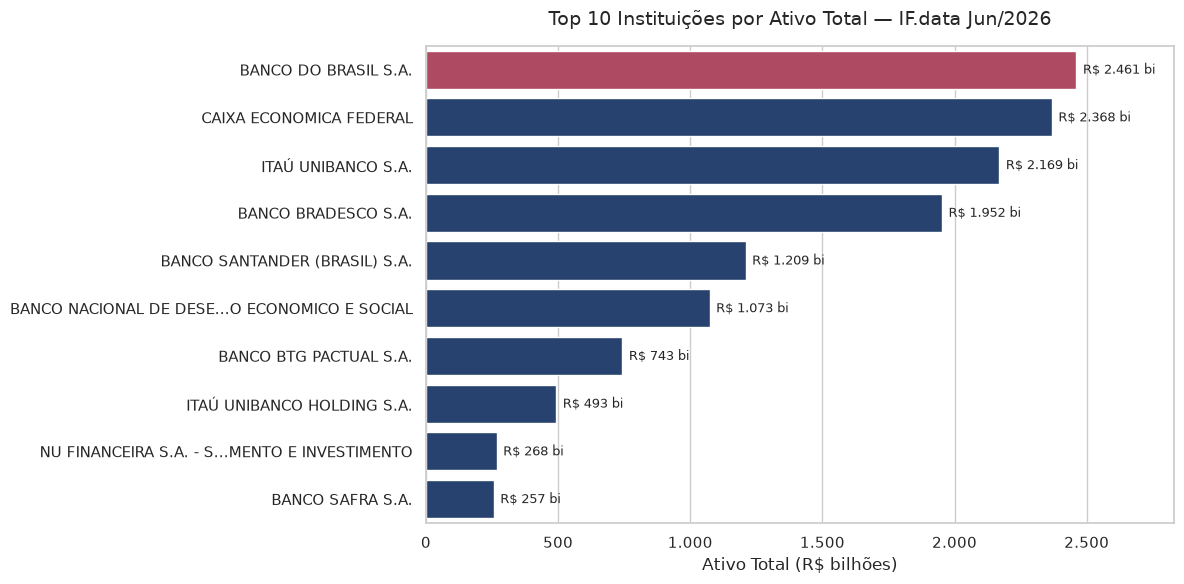

✓ top10_ativo.png


In [14]:
# Gráfico 1: Top 10 por Ativo Total
top10 = df.nlargest(10, 'Ativo Total')[['Nome_Curto', 'TCB', 'Ativo Total', 'ROE']].copy()
top10['Ativo_Bi'] = top10['Ativo Total'] / 1_000_000  # converter para R$ bilhões

fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(
    data=top10, y='Nome_Curto', x='Ativo_Bi',
    palette=[COR_DESTAQUE if i == 0 else COR_PRINCIPAL for i in range(len(top10))],
    ax=ax
)
ax.set_title('Top 10 Instituições por Ativo Total — IF.data Jun/2026', fontsize=14, pad=15)
ax.set_xlabel('Ativo Total (R$ bilhões)')
ax.set_ylabel('')
ax.set_xlim(0, top10['Ativo_Bi'].max() * 1.15)  # espaço para os rótulos
ax.xaxis.set_major_formatter(mticker.FuncFormatter(formatar_numero))
for bar in ax.patches:
    ax.text(bar.get_width() + top10['Ativo_Bi'].max() * 0.01, bar.get_y() + bar.get_height()/2,
            formatar_bi(bar.get_width()), va='center', fontsize=9)
plt.tight_layout()
plt.savefig('top10_ativo.png', dpi=150, bbox_inches='tight')
plt.show()
print('✓ top10_ativo.png')

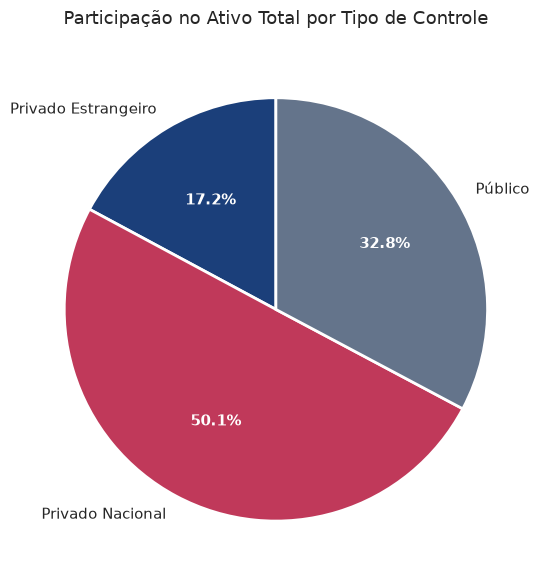

✓ ativo_controle.png


In [15]:
# Gráfico 2: Distribuição de ativo por tipo de controle
ativo_controle = df.groupby('Tipo_Controle')['Ativo Total'].sum().reset_index()
ativo_controle['pct'] = ativo_controle['Ativo Total'] / ativo_controle['Ativo Total'].sum() * 100

fig, ax = plt.subplots(figsize=(8, 6))
cores = [COR_PRINCIPAL, COR_DESTAQUE, '#64748B']
wedges, texts, autotexts = ax.pie(
    ativo_controle['Ativo Total'],
    labels=ativo_controle['Tipo_Controle'],
    autopct='%1.1f%%',
    colors=cores,
    startangle=90,
    wedgeprops={'linewidth': 2, 'edgecolor': 'white'}
)
for text in autotexts:
    text.set_fontsize(11)
    text.set_color('white')
    text.set_fontweight('bold')
ax.set_title('Participação no Ativo Total por Tipo de Controle', fontsize=13, pad=15)
plt.tight_layout()
plt.savefig('ativo_controle.png', dpi=150, bbox_inches='tight')
plt.show()
print('✓ ativo_controle.png')

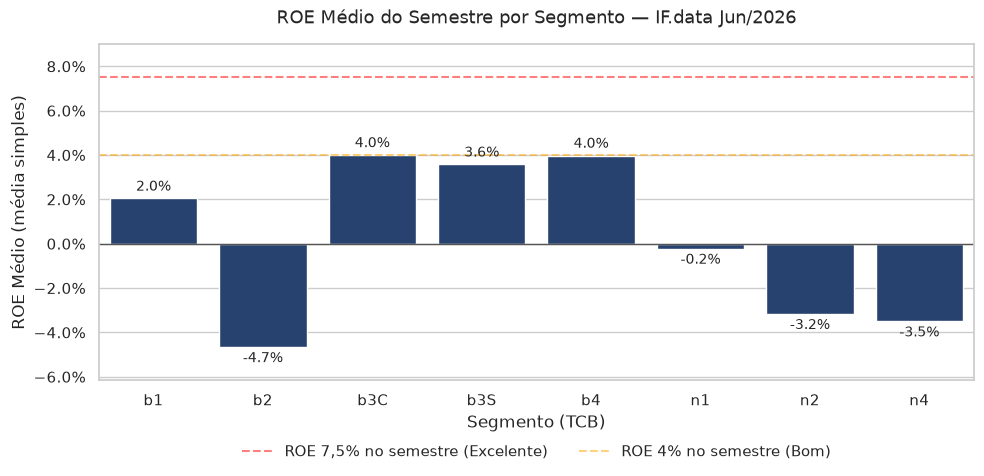

✓ roe_segmento.png


In [16]:
# Gráfico 3: ROE por segmento
roe_seg = df.groupby('TCB')['ROE'].mean().reset_index().sort_values('TCB')

fig, ax = plt.subplots(figsize=(10, 5))
cores_roe = [COR_DESTAQUE if r > ROE_EXCELENTE else COR_PRINCIPAL for r in roe_seg['ROE']]
sns.barplot(data=roe_seg, x='TCB', y='ROE', palette=cores_roe, ax=ax)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=1))
ax.axhline(ROE_EXCELENTE, color='red', linestyle='--', alpha=0.5, label='ROE 7,5% no semestre (Excelente)')
ax.axhline(ROE_BOM, color='orange', linestyle='--', alpha=0.5, label='ROE 4% no semestre (Bom)')
ax.axhline(0, color='#555555', linewidth=1)
ax.set_title('ROE Médio do Semestre por Segmento — IF.data Jun/2026', fontsize=13, pad=15)
ax.set_xlabel('Segmento (TCB)')
ax.set_ylabel('ROE Médio (média simples)')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=False)

# Rótulos nas barras: acima das positivas, abaixo das negativas
for bar in ax.patches:
    h = bar.get_height()
    if np.isnan(h):
        continue
    x = bar.get_x() + bar.get_width()/2
    if h >= 0:
        ax.text(x, h + 0.002, f'{h:.1%}', ha='center', va='bottom', fontsize=10)
    else:
        ax.text(x, h - 0.002, f'{h:.1%}', ha='center', va='top', fontsize=10)
ax.set_ylim(roe_seg['ROE'].min() - 0.015, ROE_EXCELENTE + 0.015)

plt.tight_layout()
plt.savefig('roe_segmento.png', dpi=150, bbox_inches='tight')
plt.show()
print('✓ roe_segmento.png')

Visualização

Gráfico de dispersão (scatterplot) com:
- Eixo X: `Carteira de Crédito`
- Eixo Y: `ROE`
- Cor dos pontos: `Tipo_Controle`

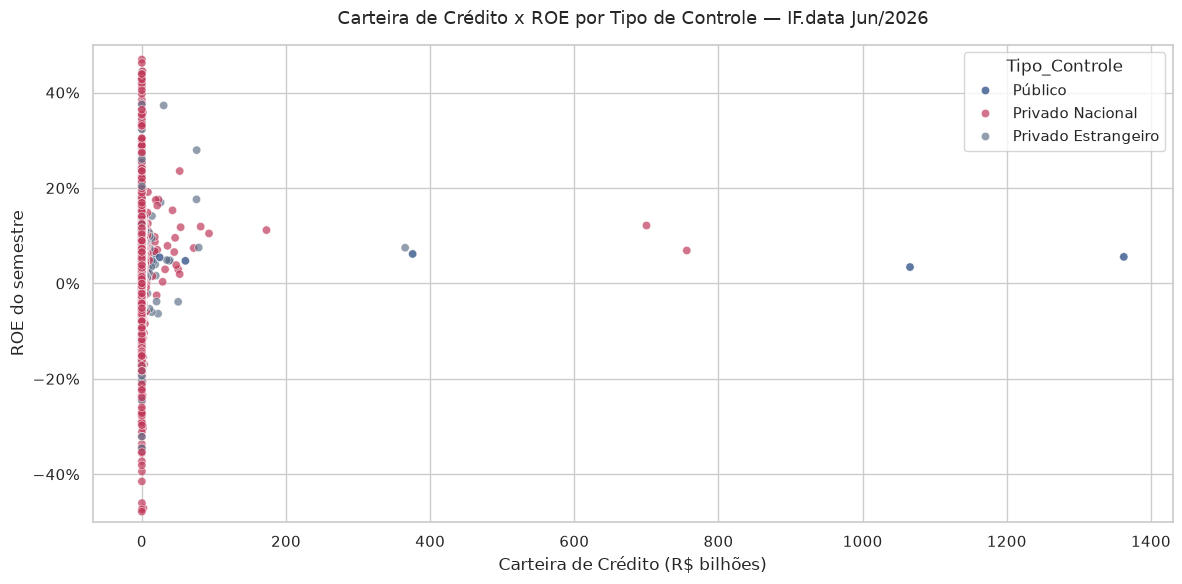

✓ saidas/credito_roe.png


In [17]:
dados_grafico = df.copy()
dados_grafico['Credito_Bi'] = dados_grafico['Carteira de Crédito'] / 1_000_000  # converter para R$ bilhões

fig, ax = plt.subplots(figsize=(12, 6))
sns.scatterplot(
    data=dados_grafico, x='Credito_Bi', y='ROE', hue='Tipo_Controle',
    palette=[COR_PRINCIPAL, COR_DESTAQUE, '#64748B'], alpha=0.7, ax=ax
)
ax.set_ylim(-0.5, 0.5)  # poucas instituições têm ROE extremo; o limite deixa o padrão visível
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=0))
ax.set_title('Carteira de Crédito x ROE por Tipo de Controle — IF.data Jun/2026', fontsize=13, pad=15)
ax.set_xlabel('Carteira de Crédito (R$ bilhões)')
ax.set_ylabel('ROE do semestre')
plt.tight_layout()
plt.savefig(f'{PASTA_SAIDAS}/credito_roe.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'✓ {PASTA_SAIDAS}/credito_roe.png')

Exportação dos Resultados

In [18]:
# Preparar tabelas para exportação
top10_export = df.nlargest(10, 'Ativo Total')[[
    'Instituição', 'TCB', 'Tipo_Controle', 'UF',
    'Ativo Total', 'Carteira de Crédito', 'Patrimônio Líquido',
    'Lucro Líquido', 'ROE', 'Classe_ROE', 'Número de Agências', 'Agencia_Fisica'
]].copy()

# ROE em texto com %, para leitura na planilha
top10_export['ROE'] = top10_export['ROE'].apply(lambda x: f'{x:.1%}' if pd.notna(x) else 'N/A')

print('Tabela pronta para exportação:')
print(top10_export[['Instituição', 'TCB', 'ROE', 'Classe_ROE']].to_string())

Tabela pronta para exportação:
                                                               Instituição TCB    ROE Classe_ROE
0                                                     BANCO DO BRASIL S.A.  b1   3.4%      Fraco
1                                                  CAIXA ECONOMICA FEDERAL  b1   5.6%        Bom
2                                                       ITAÚ UNIBANCO S.A.  b1  12.1%  Excelente
3                                                      BANCO BRADESCO S.A.  b1   6.9%        Bom
4                                            BANCO SANTANDER (BRASIL) S.A.  b1   7.5%        Bom
5                     BANCO NACIONAL DE DESENVOLVIMENTO ECONOMICO E SOCIAL  b4   6.2%        Bom
6                                                   BANCO BTG PACTUAL S.A.  b1  11.9%  Excelente
7                                               ITAÚ UNIBANCO HOLDING S.A.  b2  11.2%  Excelente
8  NU FINANCEIRA S.A. - SOCIEDADE DE CRÉDITO, FINANCIAMENTO E INVESTIMENTO  n1  27.9%  Excelente

In [19]:
# Exportar para Excel com múltiplas abas (Nome_Curto serve só aos gráficos)
base_export = df.drop(columns=['Nome_Curto'])

with pd.ExcelWriter(f'{PASTA_SAIDAS}/M6_Analise_IFdata.xlsx', engine='openpyxl') as writer:
    base_export.to_excel(writer, sheet_name='Base_Limpa', index=False)
    top10_export.to_excel(writer, sheet_name='Top10_Ativo', index=False)
    resumo_segmento.to_excel(writer, sheet_name='Resumo_Segmento')

# Exportar base limpa em CSV
base_export.to_csv(f'{PASTA_SAIDAS}/ifdata_limpo.csv', index=False, encoding='utf-8-sig')

print('✓ Arquivos exportados:')
print(f'  - {PASTA_SAIDAS}/M6_Analise_IFdata.xlsx (3 abas)')
print(f'  - {PASTA_SAIDAS}/ifdata_limpo.csv')
print('  - top10_ativo.png')
print('  - ativo_controle.png')
print('  - roe_segmento.png')
print('  - correlacao_ifdata.png')
print(f'  - {PASTA_SAIDAS}/credito_roe.png')

✓ Arquivos exportados:
  - saidas/M6_Analise_IFdata.xlsx (3 abas)
  - saidas/ifdata_limpo.csv
  - top10_ativo.png
  - ativo_controle.png
  - roe_segmento.png
  - correlacao_ifdata.png
  - saidas/credito_roe.png


Automação: Relatório por Segmento

In [20]:
def analisar_segmento(df, segmento, salvar=True):
    """Gera análise completa para um segmento do IF.data.

    Args:
        df: DataFrame limpo com os dados do IF.data
        segmento: código do segmento (ex: 'b1', 'b2')
        salvar: se True, salva o gráfico em PNG

    Returns:
        dict: estatísticas do segmento
    """
    dados = df[df['TCB'] == segmento].copy()

    if len(dados) == 0:
        return None

    # Estatísticas
    stats = {
        'segmento': segmento,
        'qtd_instituicoes': len(dados),
        'ativo_soma': dados['Ativo Total'].sum(),
        'ativo_medio': dados['Ativo Total'].mean(),
        'roe_medio': dados['ROE'].mean(),
        'roe_agregado': dados['Lucro Líquido'].sum() / dados['Patrimônio Líquido'].sum(),
        'qtd_sem_agencia': (dados['Agencia_Fisica'] == 'Sem agência').sum(),
        'pct_sem_agencia': (dados['Agencia_Fisica'] == 'Sem agência').mean()
    }

    if salvar and len(dados) >= 3:
        # Gráfico das top instituições do segmento
        top_seg = dados.nlargest(min(10, len(dados)), 'Ativo Total')
        top_seg['Ativo_Bi'] = top_seg['Ativo Total'] / 1_000_000  # converter para R$ bilhões
        fig, ax = plt.subplots(figsize=(10, max(4, len(top_seg) * 0.5)))
        sns.barplot(data=top_seg, y='Nome_Curto', x='Ativo_Bi',
                    color=COR_PRINCIPAL, ax=ax)
        ax.set_title(
            f'Segmento {segmento} — {stats["qtd_instituicoes"]} instituições\n'
            f'Ativo total: {formatar_bi(stats["ativo_soma"] / 1_000_000)}',
            fontsize=12
        )
        ax.xaxis.set_major_formatter(mticker.FuncFormatter(formatar_numero))
        ax.set_xlabel('Ativo Total (R$ bilhões)')
        ax.set_ylabel('')
        plt.tight_layout()
        plt.savefig(f'{PASTA_SAIDAS}/segmento_{segmento}.png', dpi=150, bbox_inches='tight')
        plt.close()

    return stats


# Executar para todos os segmentos
segmentos = ['b1', 'b2', 'b3S', 'b3C', 'b4', 'n1', 'n2', 'n4']
resultados = []

for seg in segmentos:
    stats = analisar_segmento(df, seg, salvar=True)
    if stats:
        resultados.append(stats)
        print(f'✓ Segmento {seg}: {stats["qtd_instituicoes"]} instituições | '
              f'ROE médio: {stats["roe_medio"]:.1%} | '
              f'ROE agregado: {stats["roe_agregado"]:.1%} | '
              f'Sem agência: {stats["pct_sem_agencia"]:.0%}')

# Salvar resultado consolidado
df_resultados = pd.DataFrame(resultados)
df_resultados.to_excel(f'{PASTA_SAIDAS}/relatorio_segmentos.xlsx', index=False)
print(f'\n✓ {PASTA_SAIDAS}/relatorio_segmentos.xlsx gerado!')

✓ Segmento b1: 114 instituições | ROE médio: 2.0% | ROE agregado: 7.1% | Sem agência: 0%


✓ Segmento b2: 50 instituições | ROE médio: -4.7% | ROE agregado: 9.7% | Sem agência: 0%


✓ Segmento b3S: 710 instituições | ROE médio: 3.6% | ROE agregado: 6.1% | Sem agência: 100%


✓ Segmento b3C: 27 instituições | ROE médio: 4.0% | ROE agregado: 3.5% | Sem agência: 100%


✓ Segmento b4: 4 instituições | ROE médio: 4.0% | ROE agregado: 6.1% | Sem agência: 0%


✓ Segmento n1: 278 instituições | ROE médio: -0.2% | ROE agregado: 8.6% | Sem agência: 0%


✓ Segmento n2: 205 instituições | ROE médio: -3.2% | ROE agregado: 9.8% | Sem agência: 0%


✓ Segmento n4: 183 instituições | ROE médio: -3.5% | ROE agregado: 8.4% | Sem agência: 0%

✓ saidas/relatorio_segmentos.xlsx gerado!


Automação: Relatório por Controle

In [21]:
def analisar_controle(df, tipo_controle, salvar=True):
    """Gera análise para um tipo de controle.

    Args:
        df: DataFrame limpo
        tipo_controle: 'Público', 'Privado Nacional' ou 'Privado Estrangeiro'
        salvar: se True, salva o gráfico

    Returns:
        dict: estatísticas
    """
    dados = df[df['Tipo_Controle'] == tipo_controle].copy()

    if len(dados) == 0:
        return None

    # Estatísticas
    stats = {
        'tipo_controle': tipo_controle,
        'qtd_instituicoes': len(dados),
        'ativo_soma': dados['Ativo Total'].sum(),
        'ativo_medio': dados['Ativo Total'].mean(),
        'roe_medio': dados['ROE'].mean(),
        'roe_agregado': dados['Lucro Líquido'].sum() / dados['Patrimônio Líquido'].sum(),
        'qtd_sem_agencia': (dados['Agencia_Fisica'] == 'Sem agência').sum(),
        'pct_sem_agencia': (dados['Agencia_Fisica'] == 'Sem agência').mean()
    }

    if salvar and len(dados) >= 3:
        # Gráfico das top instituições do tipo de controle
        top_controle = dados.nlargest(min(10, len(dados)), 'Ativo Total')
        top_controle['Ativo_Bi'] = top_controle['Ativo Total'] / 1_000_000  # converter para R$ bilhões
        fig, ax = plt.subplots(figsize=(10, max(4, len(top_controle) * 0.5)))
        sns.barplot(data=top_controle, y='Nome_Curto', x='Ativo_Bi',
                    color=COR_PRINCIPAL, ax=ax)
        ax.set_title(
            f'{tipo_controle} — {stats["qtd_instituicoes"]} instituições\n'
            f'Ativo total: {formatar_bi(stats["ativo_soma"] / 1_000_000)}',
            fontsize=12
        )
        ax.xaxis.set_major_formatter(mticker.FuncFormatter(formatar_numero))
        ax.set_xlabel('Ativo Total (R$ bilhões)')
        ax.set_ylabel('')
        plt.tight_layout()
        # Nome de arquivo sem acento e sem espaço (ex.: 'Público' -> 'publico')
        nome_arquivo = tipo_controle.lower().replace(' ', '_').replace('ú', 'u')
        plt.savefig(f'{PASTA_SAIDAS}/controle_{nome_arquivo}.png', dpi=150, bbox_inches='tight')
        plt.close()

    return stats


# Chamar em loop para os 3 tipos
tipos_controle = ['Público', 'Privado Nacional', 'Privado Estrangeiro']
resultados_controle = []

for tipo in tipos_controle:
    stats = analisar_controle(df, tipo, salvar=True)
    if stats:
        resultados_controle.append(stats)
        print(f'✓ {tipo}: {stats["qtd_instituicoes"]} instituições | '
              f'ROE médio: {stats["roe_medio"]:.1%} | '
              f'ROE agregado: {stats["roe_agregado"]:.1%} | '
              f'Sem agência: {stats["pct_sem_agencia"]:.0%}')

# Salvar resultado consolidado
df_controle = pd.DataFrame(resultados_controle)
df_controle.to_excel(f'{PASTA_SAIDAS}/relatorio_controle.xlsx', index=False)
print(f'\n✓ {PASTA_SAIDAS}/relatorio_controle.xlsx gerado!')

✓ Público: 36 instituições | ROE médio: 8.0% | ROE agregado: 5.3% | Sem agência: 0%


✓ Privado Nacional: 1311 instituições | ROE médio: 1.4% | ROE agregado: 8.5% | Sem agência: 56%


✓ Privado Estrangeiro: 224 instituições | ROE médio: -3.4% | ROE agregado: 7.7% | Sem agência: 0%

✓ saidas/relatorio_controle.xlsx gerado!


Checklist Final

In [22]:
# Checklist de qualidade do notebook
checklist = [
    ('✓', 'Imports todos na Parte 1'),
    ('✓', 'Constantes em MAIÚSCULO no início'),
    ('✓', 'Base original nunca modificada (df_raw preservado)'),
    ('✓', 'Cada etapa em célula separada com título Markdown'),
    ('✓', 'Funções com docstring explicando parâmetros e retorno'),
    ('✓', 'Gráficos salvos com plt.savefig() antes do plt.show()'),
    ('✓', 'Excel exportado com múltiplas abas organizadas'),
    ('✓', 'Células executadas em ordem (sem erros)'),
    ('✓', 'Markdown com a conclusão da análise no final'),
]

print('CHECKLIST DE QUALIDADE:')
for status, item in checklist:
    print(f'  [{status}] {item}')

CHECKLIST DE QUALIDADE:
  [✓] Imports todos na Parte 1
  [✓] Constantes em MAIÚSCULO no início
  [✓] Base original nunca modificada (df_raw preservado)
  [✓] Cada etapa em célula separada com título Markdown
  [✓] Funções com docstring explicando parâmetros e retorno
  [✓] Gráficos salvos com plt.savefig() antes do plt.show()
  [✓] Excel exportado com múltiplas abas organizadas
  [✓] Células executadas em ordem (sem erros)
  [✓] Markdown com a conclusão da análise no final


Conclusão

**Pergunta:** quão concentrado está o sistema financeiro brasileiro em junho de 2026, e o que isso muda na forma de medir rentabilidade?

**Principais achados**
1. **O ativo está em poucas mãos.** A média do Ativo Total (R$ 12,4 bi) é 42,3 vezes a mediana (R$ 293 mi). O segmento b1 (bancos comerciais, múltiplos com carteira comercial e Caixa) reúne 114 das 1.571 instituições com dados e 73,3% do ativo.
2. **Por controle, o privado nacional lidera em ativo.** Ele detém 50,1% do ativo, o público 32,8% e o estrangeiro 17,2%. As 36 instituições públicas com dados pesam muito mais do que o seu número sugere.
3. **A média simples do ROE engana.** Pela média simples, o controle público parece o mais rentável (8,0% no semestre) e o estrangeiro parece ter prejuízo (−3,4%). Pelo ROE agregado (lucro total ÷ PL total), a ordem se inverte: privado nacional 8,5%, estrangeiro 7,7% e público 5,3%. Muitas instituições pequenas com prejuízo puxam a média simples para baixo.
4. **"Sem agência" não é "digital".** As 737 instituições com zero agências são todas cooperativas (710 singulares e 27 centrais), que registram zero agências na fonte.

**Limitações**
- 51 instituições sem valores monetários (NI) ficam fora: a base analisada tem 1.571 das 1.622 instituições.
- Holdings e controladas aparecem em linhas separadas, o que gera dupla contagem: o Itaú Unibanco Holding está no top 10 ao lado do Itaú Unibanco S.A.
- O lucro é do semestre: o ROE não é anualizado, e os cortes de classificação (7,5% e 4%) são a referência anual dividida por dois.
- O ROE fica vazio para as 6 instituições com Patrimônio Líquido zero ou negativo.

**Próximos passos:** agregar por conglomerado prudencial para eliminar a dupla contagem; anualizar o ROE com PL médio; repetir a análise em outras datas-base para ver se a concentração aumenta.

*Fonte dos dados: IF.data — Banco Central do Brasil — Junho/2026 — https://www3.bcb.gov.br/ifdata*